# 05 · Content analysis

## What changed since the earlier attempt

An earlier version of this analysis modelled **titles** and found they explain 4–10% of relative
performance. That is a fact about titles. A nine-word label is not the content, and reading the low
R² as evidence that content does not matter was a mistake — content sits *upstream* of
distribution, so a weak proxy failing says nothing about the thing it proxies.

This notebook uses transcripts: 763 videos, a median of roughly 9,700 characters each, about 190
times the text in a title. Collection is documented in `04`.

## What it can and cannot answer

**Can:** what the videos are about, whether the subject matter changed across the decline, and how
different subjects performed relative to their own channel's baseline.

**Cannot:** whether content *caused* the change in reach. That needs click-through rate, average
view duration and retention, which only the channel owner sees. Nothing here separates "they made
different things" from "the algorithm treated them differently".

Runs entirely offline from files already on disk.

## 0. Environment

`%pip` installs into the kernel this notebook is running on. Installing from a terminal can land
in a different Python entirely.

In [23]:
%pip install -q scikit-learn statsmodels scipy pandas matplotlib

import sys
print("Kernel:", sys.executable)
for mod in ["pandas","numpy","matplotlib","sklearn","scipy","statsmodels"]:
    try:
        __import__(mod); print(f"  ok   {mod}")
    except ImportError as e:
        print(f"  FAIL {mod} -> {e}")


[notice] A new release of pip is available: 26.1 -> 26.1.2
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Kernel: /opt/homebrew/opt/python@3.11/bin/python3.11
  ok   pandas
  ok   numpy
  ok   matplotlib
  ok   sklearn
  ok   scipy
  ok   statsmodels


In [24]:
import json, pathlib, re
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest

CWD = pathlib.Path.cwd()
NB = next((p for p in [CWD, CWD/"notebook", *CWD.parents] if (p/"data").is_dir()), CWD)
DATA, FIG = NB/"data", NB/"figures"; FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

# keep="last": a video refused early and retrieved later appears twice.
tr = (pd.DataFrame([json.loads(l) for l in (DATA/"content/transcripts.jsonl").open() if l.strip()])
        .drop_duplicates("id", keep="last"))
tr = tr[tr.status == "ok"][["id", "transcript"]]

vids = pd.read_csv(DATA/"videos_clean.csv", parse_dates=["date"])
m = tr.merge(vids[["id", "channel", "title", "date", "views", "likes",
                   "comments", "rbi", "duration_min"]], on="id")
m["window"] = np.where(m.date < "2023-07-01", "pre", "post")

print(f"{len(m)} transcripts · {(m.window=='pre').sum()} before the decline, "
      f"{(m.window=='post').sum()} after")
print(f"Median length {m.transcript.str.len().median():,.0f} characters")
print(m.channel.value_counts().to_string())

763 transcripts · 418 before the decline, 345 after
Median length 9,664 characters
channel
LinusTechTips    224
ShortCircuit     186
TechLinked       184
Techquickie      169


## 1. Topics

TF-IDF over unigrams and bigrams, reduced with SVD, clustered with k-means. Spoken transcripts
need filler removed — *uh, um, like, you know, gonna* — or the clusters organise around speech
habits rather than subject matter.

> Sentence embeddings would represent meaning better than term frequencies, and the pipeline below
> would accept them as a drop-in replacement for `X`. TF-IDF is used because it was the version I
> could verify end to end. On documents this long the difference is smaller than it would be on
> titles — with 9,700 characters, term overlap alone is fairly informative.

In [25]:
FILLER = r"\b(uh|um|like|you know|i mean|kind of|sort of|gonna|wanna|okay|alright|yeah|so|right)\b"

def clean(t):
    t = re.sub(r"[^a-z0-9 ]", " ", str(t).lower())
    return re.sub(r"\s+", " ", re.sub(FILLER, " ", t)).strip()

m["txt"] = m.transcript.map(clean)

STOP = ("the a an and or of to in on for with is are this that we i you my our it its at by from "
        "as be new video do does did can will just get got make made most best but not out up all "
        "more very vs your what why how much many when who has have had been was were there here "
        "now then also one two three into over about after before than them their these those go "
        "going want really actually think see look thing things guys today let lets need put take "
        "come said say little bit lot pretty good great big time way well because if then").split()

vec = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), min_df=8, max_df=0.5,
                      sublinear_tf=True, stop_words=STOP)
X = vec.fit_transform(m.txt)
Z = TruncatedSVD(150, random_state=0).fit_transform(X)
Z = Z/np.clip(np.linalg.norm(Z, axis=1, keepdims=True), 1e-9, None)

km = KMeans(12, n_init=6, random_state=0).fit(Z)
m["cluster"] = km.labels_
m_all = m.copy()   # kept for the parameter-stability check in 1b
terms = np.array(vec.get_feature_names_out())

print(f"{X.shape[0]} documents · {X.shape[1]:,} terms · 12 clusters")
print(f"Largest cluster holds {pd.Series(km.labels_).value_counts(normalize=True).iloc[0]:.0%} "
      f"of documents\n")
print("(On titles the largest cluster held 44%, on descriptions 34%. Longer documents")
print(" separate better — most titles simply lack enough distinctive terms.)\n")

for k in pd.Series(km.labels_).value_counts().index:
    sel = km.labels_ == k
    top = terms[np.asarray(X[sel].mean(axis=0)).ravel().argsort()[::-1][:8]]
    print(f"[{k:>2}] n={sel.sum():>3}  {', '.join(top)}")

763 documents · 11,393 terms · 12 clusters
Largest cluster holds 19% of documents

(On titles the largest cluster held 44%, on descriptions 34%. Longer documents
 separate better — most titles simply lack enough distinctive terms.)

[ 8] n=147  windows, pc, microsoft, system, computer, data, called, check other
[ 9] n=104  ai, google, company, news, tech, apple, he, tech news
[ 1] n= 89  cpu, motherboard, fine, cable, nice, water, fans, fan
[ 5] n= 88  nice, cable, button, feel, buttons, side, feels, stuff
[ 4] n= 80  news, tech news, quick bits, tech, apple, bits, riley, google
[ 2] n= 58  gpu, performance, amd, cpu, nvidia, memory, card, rtx
[ 3] n= 47  monitor, display, hdmi, 4k, hdr, monitors, color, hertz
[ 7] n= 45  phone, camera, charging, pro, battery, button, iphone, megapixel
[ 6] n= 42  router, data, wi fi, pci, wi, fi, pci express, express
[ 0] n= 38  laptop, keyboard, laptops, battery, thunderbolt, display, 16, webcam
[10] n= 15  freshbooks, required freshbooks, freshbooks

In [26]:
# Labels assigned by reading the top terms and a sample of titles from each cluster.
# Two clusters are sponsor reads that survived cleaning — the ad copy is long enough
# and consistent enough to cluster on its own. They are dropped, not relabelled.
NAMES = {8: "OS / Windows / software", 9: "AI & industry news", 1: "PC internals & cooling",
         5: "Hands-on / build quality", 4: "Tech news roundup", 2: "GPUs & CPUs",
         3: "Displays", 7: "Phones & cameras", 6: "Networking", 0: "Laptops",
         10: "[sponsor read]", 11: "[sponsor read]"}
m["topic"] = m.cluster.map(NAMES)

dropped = m.topic.str.startswith("[").sum()
m = m[~m.topic.str.startswith("[")].copy()
print(f"Dropped {dropped} documents in two sponsor-read clusters ({dropped/(len(m)+dropped):.0%})")
print(f"{len(m)} remain · {(m.window=='pre').sum()} before, {(m.window=='post').sum()} after")
m.drop(columns=["transcript", "txt"]).to_csv(DATA/"transcript_topics.csv", index=False)

Dropped 25 documents in two sponsor-read clusters (3%)
738 remain · 393 before, 345 after


## 1b. Choosing the parameters

Two numbers were set by hand: 150 SVD components and 12 clusters. Neither has been justified, and
the same objection was raised elsewhere in this project about the rolling baseline window. It
deserves the same treatment.

Two standard diagnostics are run below. Both fail to select a value — which is worth reporting
rather than hiding, because the reason they fail is informative about the data.

In [27]:
from sklearn.metrics import silhouette_score

# --- Diagnostic 1: how many components? --------------------------------------
sv   = TruncatedSVD(300, random_state=0).fit(X)
cum  = np.cumsum(sv.explained_variance_ratio_)
marg = np.diff(np.concatenate([[0], cum]))

print("Cumulative explained variance\n")
for n in [20, 50, 100, 150, 200, 300]:
    print(f"  {n:>3} components   {cum[n-1]:.1%}")
print("\nNo elbow. The curve is smooth and concave the whole way: marginal gain per")
print("component decays gradually with no break after which adding components stops")
print("paying. This is normal for TF-IDF, where variance is spread thinly across many")
print("directions. Note that even 300 components account for only 58% of it.")

# --- Diagnostic 2: how many clusters? ----------------------------------------
KS, sil, share = [6, 8, 10, 12, 14, 16, 20], [], []
for K in KS:
    km_t = KMeans(K, n_init=5, random_state=0).fit(Z)
    sil.append(silhouette_score(Z, km_t.labels_))
    share.append(pd.Series(km_t.labels_).value_counts(normalize=True).iloc[0])

print("\n\nSilhouette by k\n")
print(f"{'k':>3}{'silhouette':>13}{'largest cluster':>18}")
for K, s, sh in zip(KS, sil, share):
    print(f"{K:>3}{s:>13.4f}{sh:>17.0%}")
print("\nThe score dips from k=6 to k=8, recovers, and then climbs steadily to the")
print("largest k tested. There is no interior maximum: the best value is always at")
print("the edge of the search, so the statistic never selects a k. Taken at face")
print("value it would push k upward until every document is its own cluster.")
print("\nIt is also tiny in absolute terms. On sparse high-dimensional text almost")
print("every point sits near a cluster boundary, so a 'good' clustering here still")
print("scores around 0.03, against the 0.25+ usually read as real separation.")
print("Reading these values as quality scores would be a misuse of the statistic.")

Cumulative explained variance

   20 components   10.5%
   50 components   18.2%
  100 components   28.2%
  150 components   36.9%
  200 components   44.5%
  300 components   57.6%

No elbow. The curve is smooth and concave the whole way: marginal gain per
component decays gradually with no break after which adding components stops
paying. This is normal for TF-IDF, where variance is spread thinly across many
directions. Note that even 300 components account for only 58% of it.


Silhouette by k

  k   silhouette   largest cluster
  6       0.0288              24%
  8       0.0222              26%
 10       0.0230              17%
 12       0.0273              21%
 14       0.0315              13%
 16       0.0336              12%
 20       0.0369              10%

The score dips from k=6 to k=8, recovers, and then climbs steadily to the
largest k tested. There is no interior maximum: the best value is always at
the edge of the search, so the statistic never selects a k. Taken at face


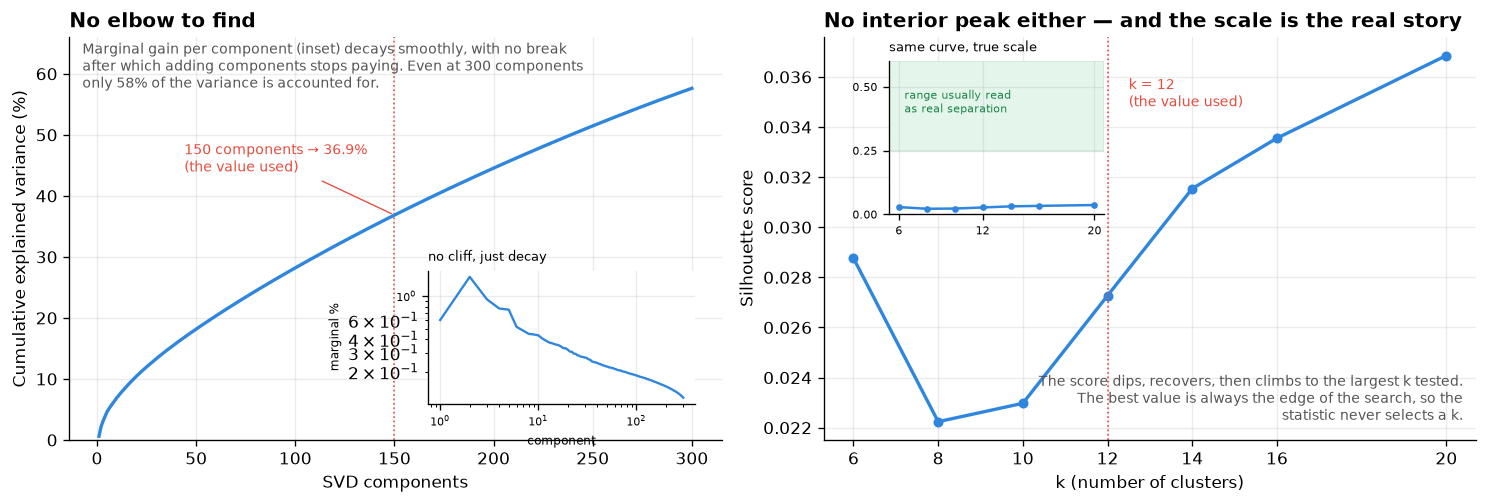

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
n = np.arange(1, len(cum)+1)

ax[0].plot(n, cum*100, color="#2E86DE", lw=2, zorder=3)
ax[0].axvline(150, color="#E74C3C", lw=1, ls=":", zorder=1)
ax[0].annotate(f"150 components \u2192 {cum[149]:.1%}\n(the value used)",
               xy=(150, cum[149]*100), xytext=(44, 44), fontsize=8.5, color="#E74C3C",
               arrowprops=dict(arrowstyle="-", color="#E74C3C", lw=.8))
ax[0].set_xlabel("SVD components"); ax[0].set_ylabel("Cumulative explained variance (%)")
ax[0].set_ylim(0, 66); ax[0].set_title("No elbow to find", loc="left", weight="bold")
ax[0].text(.02, .99,
           "Marginal gain per component (inset) decays smoothly, with no break\n"
           "after which adding components stops paying. Even at 300 components\n"
           f"only {cum[-1]:.0%} of the variance is accounted for.",
           transform=ax[0].transAxes, ha="left", va="top", fontsize=8.2, color="#555")
i0 = ax[0].inset_axes([.55, .09, .41, .33])
i0.loglog(n, marg*100, color="#2E86DE", lw=1.4)
i0.set_xlabel("component", fontsize=7); i0.set_ylabel("marginal %", fontsize=7)
i0.tick_params(labelsize=6.5); i0.set_title("no cliff, just decay", fontsize=7.5, loc="left")
for s in ["top", "right"]: i0.spines[s].set_visible(False)

ax[1].plot(KS, sil, "o-", color="#2E86DE", lw=2, ms=5)
ax[1].axvline(12, color="#E74C3C", lw=1, ls=":")
ax[1].annotate("k = 12\n(the value used)", xy=(12, sil[KS.index(12)]),
               xytext=(12.5, max(sil)*.945), fontsize=8.5, color="#E74C3C")
ax[1].set_xlabel("k (number of clusters)"); ax[1].set_ylabel("Silhouette score")
ax[1].set_title("No interior peak either \u2014 and the scale is the real story",
                loc="left", weight="bold")
ax[1].set_xticks(KS)
ax[1].text(.98, .05,
           "The score dips, recovers, then climbs to the largest k tested.\n"
           "The best value is always the edge of the search, so the\n"
           "statistic never selects a k.",
           transform=ax[1].transAxes, ha="right", fontsize=8.2, color="#555")
ins = ax[1].inset_axes([.10, .56, .33, .38])
ins.plot(KS, sil, "o-", color="#2E86DE", lw=1.5, ms=3)
ins.axhspan(.25, .6, color="#27AE60", alpha=.12); ins.set_ylim(0, .6)
ins.set_xticks([6, 12, 20]); ins.set_yticks([0, .25, .5]); ins.tick_params(labelsize=6.5)
ins.text(6.4, .40, "range usually read\nas real separation", fontsize=6.3, color="#1E8449")
ins.set_title("same curve, true scale", fontsize=7.5, loc="left")

for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG/"parameter_diagnostics.png", bbox_inches="tight")
plt.show()

> **How to read this.** Both panels are negative results, drawn deliberately.
>
> On the left, an elbow would appear as a visible knee — a point where the curve flattens and
> further components add nothing. There isn't one, and the inset shows why: marginal gain decays
> as a smooth power law rather than falling off a cliff.
>
> On the right, a well-separated clustering would show a hump, with silhouette peaking at the
> right k. Instead the score has no interior maximum, and the inset puts it on the scale it is
> normally read against — every value sits near zero. Neither statistic chooses a parameter here,
> so 150 and 12 are justified by the stability check below instead: whether the finding survives
> when both are varied.

### Since the diagnostics choose nothing, test whether the conclusion depends on the choice

The parameters cannot be optimised, so the question becomes whether they matter. Fifteen
configurations — three component counts by five values of k — and for each, one question:

*Which cluster do TechLinked's post-decline videos concentrate in, and what is it about?*

Cluster labels are arbitrary and change between runs, so the comparison ignores them entirely and
looks only at the top terms and the concentration.

In [29]:
rows = []
for ncomp in [100, 150, 200]:
    Zi = TruncatedSVD(ncomp, random_state=0).fit_transform(X)
    Zi = Zi/np.clip(np.linalg.norm(Zi, axis=1, keepdims=True), 1e-9, None)
    for K in [8, 10, 12, 16, 20]:
        lab = KMeans(K, n_init=5, random_state=0).fit(Zi).labels_
        tmp = m_all.assign(c=lab)
        tl = tmp[tmp.channel == "TechLinked"]
        post, pre = tl[tl.window == "post"], tl[tl.window == "pre"]
        top_c = post.c.value_counts().index[0]
        words = terms[np.asarray(X[lab == top_c].mean(axis=0)).ravel().argsort()[::-1][:4]]
        rows.append({"components": ncomp, "k": K,
                     "top_terms": ", ".join(words),
                     "post_concentration": round((post.c == top_c).mean(), 2),
                     "pre_in_same": round((pre.c == top_c).mean(), 2)})

stab = pd.DataFrame(rows)
print("Where TechLinked's post-decline videos land, across 15 configurations\n")
print(stab.to_string(index=False))

hits = stab.top_terms.str.contains("ai").sum()
print(f"\n'ai' is a top term of that cluster in {hits} of {len(stab)} configurations.")
print(f"Post-decline concentration ranges {stab.post_concentration.min():.0%}"
      f"–{stab.post_concentration.max():.0%}; the pre-decline share of the same cluster"
      f" ranges {stab.pre_in_same.min():.0%}–{stab.pre_in_same.max():.0%}.")
stab.to_csv(DATA/"cluster_stability.csv", index=False)

Where TechLinked's post-decline videos land, across 15 configurations

 components  k                 top_terms  post_concentration  pre_in_same
        100  8 ai, company, google, news                0.90         0.25
        100 10 ai, google, company, news                0.90         0.20
        100 12 ai, company, google, news                0.89         0.25
        100 16 ai, company, google, news                0.90         0.24
        100 20 ai, company, google, news                0.88         0.23
        150  8 ai, company, google, news                0.95         0.21
        150 10 ai, google, company, news                0.89         0.20
        150 12 ai, google, company, news                0.83         0.20
        150 16 ai, company, news, google                0.84         0.18
        150 20 ai, google, company, news                0.65         0.21
        200  8 ai, google, company, news                0.88         0.21
        200 10 ai, company, news, google 

> **How to read this.** Concentration falls at k=16 and k=20 because more clusters split the AI
> material across several of them — a mechanical effect of the parameter, not a change in the
> finding. The ordering never reverses: after the decline TechLinked's output sits overwhelmingly
> in an AI-dominated cluster, before it, roughly a fifth did.
>
> So the honest position on both parameters is: **neither is optimal, neither can be shown to be,
> and the result does not depend on either.** That is a weaker statement than "k=12 is correct",
> and it is the one the data supports.
>
> The same reasoning was applied to the rolling baseline window in `02`, where the diagnostics
> were also flat. When a hyperparameter cannot be justified, showing the conclusion survives it is
> the available defence.

## 2. Did the subject matter change?

In [30]:
ct = pd.crosstab(m.topic, m.window)
mix = pd.crosstab(m.topic, m.window, normalize="columns").mul(100).round(1)
mix["change"] = (mix.post - mix.pre).round(1)
mix["n_pre"], mix["n_post"] = ct.pre, ct.post
print("Share of transcripts by topic (%)\n")
print(mix.sort_values("change", ascending=False).to_string())

chi2, p, dof, _ = chi2_contingency(ct)
print(f"\nChi-square test of independence: χ²={chi2:.1f}, df={dof}, p={p:.2e}")
print("The mix changed. Which topics moved:\n")
for tp in ct.index:
    z, pv = proportions_ztest([ct.loc[tp, "post"], ct.loc[tp, "pre"]],
                              [ct["post"].sum(), ct["pre"].sum()])
    if pv < 0.10:
        print(f"  {tp:<26} {mix.loc[tp,'pre']:>5.1f}% → {mix.loc[tp,'post']:>5.1f}%   p={pv:.3f}")

Share of transcripts by topic (%)

window                    post   pre  change  n_pre  n_post
topic                                                      
AI & industry news        23.8   5.6    18.2     22      82
OS / Windows / software   24.3  16.0     8.3     63      84
Networking                 6.7   4.8     1.9     19      23
PC internals & cooling    12.5  11.7     0.8     46      43
Laptops                    4.9   5.3    -0.4     21      17
Hands-on / build quality  11.0  12.7    -1.7     50      38
Displays                   5.2   7.4    -2.2     29      18
Phones & cameras           4.3   7.6    -3.3     30      15
GPUs & CPUs                5.8   9.7    -3.9     38      20
Tech news roundup          1.4  19.1   -17.7     75       5

Chi-square test of independence: χ²=111.9, df=9, p=5.98e-20
The mix changed. Which topics moved:

  AI & industry news           5.6% →  23.8%   p=0.000
  GPUs & CPUs                  9.7% →   5.8%   p=0.051
  OS / Windows / software     16.0% 

### The obvious reading is wrong

The two largest moves are AI content rising from 5.6% to 23.8% and general tech news collapsing
from 19.1% to 1.4%. Read at company level that says *the business pivoted into AI coverage*.

Before reporting that, check whether the two clusters are independent categories or one channel's
output being re-sorted as its subject matter drifted.

In [31]:
for tp in ["AI & industry news", "Tech news roundup"]:
    s = m[m.topic == tp]
    print(f"{tp}  (n={len(s)})")
    print(f"  by channel: {s.channel.value_counts().to_dict()}\n")

print("Both are essentially one channel. Within TechLinked alone:\n")
tl = m[m.channel == "TechLinked"]
print(pd.crosstab(tl.topic, tl.window, normalize="columns").mul(100).round(1).to_string())

print("\n\nExcluding TechLinked, does AI content still grow?\n")
o = m[m.channel != "TechLinked"]
octb = pd.crosstab(o.topic, o.window)
omix = pd.crosstab(o.topic, o.window, normalize="columns").mul(100).round(1)
omix["change"] = (omix.post - omix.pre).round(1)
print(omix.sort_values("change", ascending=False).head(5).to_string())
if "AI & industry news" in octb.index:
    z, pv = proportions_ztest([octb.loc["AI & industry news", "post"],
                               octb.loc["AI & industry news", "pre"]],
                              [octb["post"].sum(), octb["pre"].sum()])
    print(f"\n  AI content excluding TechLinked: "
          f"{omix.loc['AI & industry news','pre']:.1f}% → "
          f"{omix.loc['AI & industry news','post']:.1f}%   p={pv:.4f}")

AI & industry news  (n=104)
  by channel: {'TechLinked': 95, 'LinusTechTips': 6, 'Techquickie': 3}

Tech news roundup  (n=80)
  by channel: {'TechLinked': 80}

Both are essentially one channel. Within TechLinked alone:

window                   post   pre
topic                              
AI & industry news       89.2  21.2
OS / Windows / software   4.8   3.0
Tech news roundup         6.0  75.8


Excluding TechLinked, does AI content still grow?

window                   post   pre  change
topic                                      
OS / Windows / software  30.5  20.4    10.1
AI & industry news        3.1   0.3     2.8
Networking                8.8   6.5     2.3
PC internals & cooling   16.4  15.6     0.8
Laptops                   6.5   7.1    -0.6

  AI content excluding TechLinked: 0.3% → 3.1%   p=0.0114


> **What the check establishes.** Both clusters are TechLinked, and inside that channel general
> tech news went from 75.8% to 6.0% while AI went from 21.2% to 89.2%. These are not two
> categories trading places — they are **one channel's daily news programme becoming a daily AI
> programme**, and the clustering separating the before and after as different topics is the
> evidence of how complete the shift was.
>
> Excluding TechLinked, AI content grows from 0.3% to 3.1%. Statistically significant, negligible
> in absolute terms.
>
> **So "the company pivoted into AI" is wrong. One of four channels did, almost entirely.** The
> aggregate number would have supported the broader claim, and the broader claim would have been
> more quotable. It is also not what happened.

## 3. Did any subject perform better?

The rolling baseline index divides each video by the median of the nine that preceded it on the
same channel, so 1.0 means a video matched its recent neighbours. Era and channel scale are held
approximately constant by construction. From `02`: this index is descriptive and cannot carry
p-values, so what follows is a ranking, not a test.

In [32]:
perf = (m.groupby("topic")
          .agg(n=("id", "size"), rbi=("rbi", "median"), median_views=("views", "median"),
               likes=("likes", "sum"), views=("views", "sum"), comments=("comments", "sum"))
          .assign(like_pct=lambda x: (x.likes/x.views*100).round(2),
                  comment_per_1k=lambda x: (x.comments/x.views*1000).round(2))
          .drop(columns=["likes", "views", "comments"])
          .sort_values("rbi", ascending=False))
perf["rbi"] = perf.rbi.round(2)
print(perf.to_string())

print(f"\nRange {perf.rbi.min():.2f} to {perf.rbi.max():.2f}. On titles the same exercise gave")
print("0.92 to 1.13 — transcripts separate subjects more sharply, but the spread is still")
print("modest. Subject choice is not the dominant driver of relative performance.")
perf.to_csv(DATA/"topic_performance.csv")

                            n   rbi  median_views  like_pct  comment_per_1k
topic                                                                      
Networking                 42  1.23      457057.0      4.41            1.72
Laptops                    38  1.07      775858.5      3.29            1.75
GPUs & CPUs                58  1.04     1779305.0      3.74            2.27
AI & industry news        104  1.02      468341.0      4.97            2.81
Tech news roundup          80  1.01      535204.0      5.89            2.58
PC internals & cooling     89  1.01     2034010.0      3.02            1.46
OS / Windows / software   147  0.99      417290.0      4.22            1.23
Displays                   47  0.97      754470.0      3.38            1.90
Phones & cameras           45  0.95      641446.0      3.21            2.12
Hands-on / build quality   88  0.78      593463.5      3.77            2.39

Range 0.78 to 1.23. On titles the same exercise gave
0.92 to 1.13 — transcripts separat

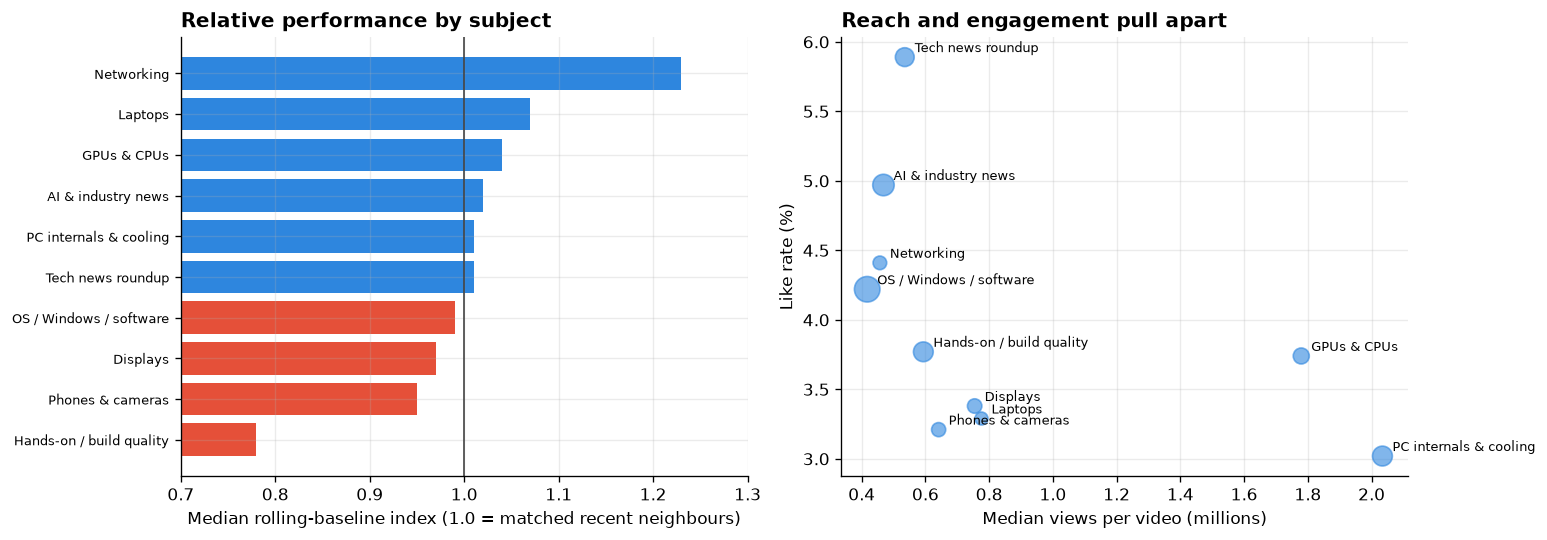

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

p2 = perf.sort_values("rbi")
y = np.arange(len(p2))
ax[0].barh(y, p2.rbi, color=np.where(p2.rbi >= 1, "#2E86DE", "#E55039"))
ax[0].axvline(1, color="#444", lw=1)
ax[0].set_yticks(y); ax[0].set_yticklabels(p2.index, fontsize=8)
ax[0].set_xlabel("Median rolling-baseline index (1.0 = matched recent neighbours)")
ax[0].set_title("Relative performance by subject", loc="left", weight="bold")
ax[0].set_xlim(0.7, 1.3)

ax[1].scatter(perf.median_views/1e6, perf.like_pct, s=perf.n*1.6,
              color="#2E86DE", alpha=.6, zorder=3)
for tp, r in perf.iterrows():
    ax[1].annotate(tp, (r.median_views/1e6, r.like_pct), xytext=(6, 3),
                   textcoords="offset points", fontsize=7.5)
ax[1].set_xlabel("Median views per video (millions)")
ax[1].set_ylabel("Like rate (%)")
ax[1].set_title("Reach and engagement pull apart", loc="left", weight="bold")

plt.tight_layout(); plt.savefig(FIG/"topic_performance.png", bbox_inches="tight"); plt.show()

> **The right-hand panel is the one worth pausing on.** The subjects that reach the most people
> are not the ones that get the most response per viewer. PC internals reaches roughly two million
> per video at the *lowest* like rate in the set; tech news reaches a quarter of that at the
> highest. This is the same pattern `02` found across channels — the flagship reaches widest and
> shallowest — showing up again at subject level.
>
> Which of the two is worth more depends on what the audience is for. A viewer who watches and
> leaves is worth something to an advertiser and very little to a storefront.

## 4. Did the pivot pay?

TechLinked moved almost its entire output into one subject. Whether that worked is a question the
index can answer descriptively.

In [34]:
tl = m[m.channel == "TechLinked"]
print("TechLinked, by subject and period — index relative to its own recent neighbours\n")
print(tl.pivot_table(index="topic", columns="window", values="rbi",
                     aggfunc="median").round(2).to_string())
print("\nCounts")
print(pd.crosstab(tl.topic, tl.window).to_string())

ai = tl[tl.topic == "AI & industry news"]
print(f"\nAI content on TechLinked: median index {ai.rbi.median():.2f} across {len(ai)} videos.")
print("An index near 1.0 means these videos performed like the channel's other videos at the")
print("time — the shift did not buy outperformance relative to its own baseline.")
print("\nWhat this cannot tell you: what would have happened without the shift. The baseline")
print("is the channel's own recent output, which after 2023 is mostly AI content too. A pivot")
print("that arrested a decline would look identical to one that did nothing.")

TechLinked, by subject and period — index relative to its own recent neighbours

window                   post   pre
topic                              
AI & industry news       1.04  1.02
OS / Windows / software  1.04  2.84
Tech news roundup        0.87  1.02

Counts
window                   post  pre
topic                             
AI & industry news         74   21
OS / Windows / software     4    3
Tech news roundup           5   75

AI content on TechLinked: median index 1.03 across 95 videos.
An index near 1.0 means these videos performed like the channel's other videos at the
time — the shift did not buy outperformance relative to its own baseline.

What this cannot tell you: what would have happened without the shift. The baseline
is the channel's own recent output, which after 2023 is mostly AI content too. A pivot
that arrested a decline would look identical to one that did nothing.


## 5. What this adds

**One channel's editorial identity changed completely.** TechLinked's daily technology news became
a daily AI news programme — 75.8% general coverage to 6.0%, 21.2% AI to 89.2%. Clustering placed
the before and after in different topics without being told to.

**The company did not pivot; a channel did.** Excluding TechLinked, AI content moved from 0.3% to
3.1% of output. The aggregate figure supported a much bigger claim than the data does.

**Subject choice explains less than expected.** Relative performance ranges 0.78 to 1.23 across ten
subjects — real, but modest. Whatever drives the variation, it is mostly not *what* the video is
about.

**Reach and engagement point in different directions.** The highest-reach subjects have the lowest
like rates. For a company whose storefront depends on affiliation rather than on impressions, that
distinction matters more than the reach numbers alone suggest.

### Limits

Transcripts cover 763 videos from a stratified sample of 600 plus earlier retrievals, not the full
catalogue. Balance across channel and period was verified in `04`; volume was not the constraint,
coverage balance was.

A transcript records what was said, not how well. Production, editing, host performance and whether
the subject was inherently interesting are all invisible here.

And the causal question stays open. Content precedes distribution, but separating them needs
click-through rate, view duration and retention — none of which is public.